# Notebook 04: Aspect-based sentiment analysis

**Goal:** go beyond one score per review and find out **what** customers like or dislike: battery, camera, price, delivery and so on.

**Input:** `data/processed/reviews_electronics_clean.csv` and the model saved by notebook 03 (`models/best_model.pkl`)
**Output:** `reports/aspect_sentiment.csv`, `reports/aspect_sentiment.png`

**Why this matters:** the review "camera is great but battery is bad" is positive about one thing and negative about another. A single "neutral" score hides both facts. A seller reading thousands of reviews wants to know "battery: 40% negative", not just "overall 78% positive".

**What we do, in order**
1. Load the data and the trained model
2. See how we split reviews into clauses and spot aspects (a keyword method)
3. Extract aspect clauses from all reviews
4. Score the sentiment of each clause with our model
5. Summarise sentiment per aspect and draw a chart
6. Check the quality by reading real examples
7. Drill down into one product
8. Save the results

## Step 0: Setup

In [1]:
import os, sys
root = os.getcwd() if os.path.isdir("src") else os.path.abspath("..")
os.chdir(root)
sys.path.insert(0, root)

import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display

from src.preprocess import clean_text
from src.aspects import ASPECTS, split_clauses, find_aspects, extract_aspect_clauses

pd.set_option("display.max_colwidth", 100)
LABELS = ["negative", "neutral", "positive"]

## Step 1: Load the data and the trained model

We reuse the vectorizer and classifier saved in notebook 03, so the whole project is one connected pipeline: the same model that scores whole reviews now scores pieces of reviews.

In [2]:
elec = pd.read_csv("data/processed/reviews_electronics_clean.csv")
elec = elec.dropna(subset=["Summary"]).reset_index(drop=True)

vec, model = joblib.load("models/best_model.pkl")
print(len(elec), "reviews loaded; model type:", type(model).__name__)

67401 reviews loaded; model type: LinearSVC


## Step 2: How we find aspects

Our method has two simple parts. You can read the code in `src/aspects.py`.

1. **Split a review into clauses** at punctuation and words like "but" / "however", so each clause talks about roughly one thing.
2. **Match keywords:** each aspect has a list of keywords (for example battery: "battery", "backup", "charging"). If a clause contains one, the clause is about that aspect.

This is a *dictionary (keyword) method*. Its strength is that it is transparent and easy to check. Its weakness is that it can only find aspects whose words we listed.

Here are our aspects and an example of the method in action:

In [3]:
print("Aspects:", ", ".join(ASPECTS))
print()
for text in ["Camera is great but battery is bad",
             "Good phone, fast delivery and nice display",
             "sound and picture quality is good",
             "super"]:
    print(repr(text))
    print("   clauses:", split_clauses(text))
    print("   aspects:", extract_aspect_clauses(text))

Aspects: battery, camera, display, sound, performance, price, build quality, design, connectivity, delivery, heating, cooling, noise

'Camera is great but battery is bad'
   clauses: ['camera is great', 'battery is bad']
   aspects: [('camera', 'camera is great'), ('battery', 'battery is bad')]
'Good phone, fast delivery and nice display'
   clauses: ['good phone', 'fast delivery', 'nice display']
   aspects: [('delivery', 'fast delivery'), ('display', 'nice display')]
'sound and picture quality is good'
   clauses: ['sound and picture quality is good']
   aspects: [('display', 'sound and picture quality is good'), ('sound', 'sound and picture quality is good')]
'super'
   clauses: ['super']
   aspects: []


**What to notice:** the first review becomes two clauses with different aspects. The last review ("super") mentions no aspect, so it gives nothing; that is normal, since many reviews are just a general comment.

## Step 3: Extract aspect clauses from all reviews

For each review we collect every `(aspect, clause)` pair. Then we attach the product name and star rating so we can analyse by product later.

In [4]:
records = []
for review_id, text in zip(elec.index, elec["Summary"].astype(str)):
    for aspect, clause in extract_aspect_clauses(text):
        records.append((review_id, aspect, clause))

clauses = pd.DataFrame(records, columns=["review_id", "aspect", "clause"])
clauses = clauses.join(elec[["product_name", "Rate", "label"]], on="review_id")

covered = clauses["review_id"].nunique()
print(f"{covered} of {len(elec)} reviews ({covered / len(elec):.1%}) mention at least one aspect")
print(len(clauses), "aspect mentions in total")
clauses["aspect"].value_counts()

28219 of 67401 reviews (41.9%) mention at least one aspect
47568 aspect mentions in total


aspect
price            10296
sound             6807
build quality     6757
connectivity      4078
design            3894
performance       3814
delivery          3636
battery           2899
display           1741
heating           1467
camera             869
noise              793
cooling            517
Name: count, dtype: int64

**What to notice:** only a part of the reviews mention a specific aspect. Most are general ("good", "nice product"). That is a real property of this data, and a fair limitation to mention in your report.

## Step 4: Score the sentiment of each clause

We clean each clause exactly like the training data (`clean_text`) and let the model predict its sentiment. We skip clauses with fewer than 2 words after cleaning ("battery" alone says nothing about sentiment).

*Important idea:* the model was trained on whole reviews, but it still works reasonably on short clauses because the sentiment words ("bad", "great") are what it relies on.

In [5]:
clauses["clean"] = clauses["clause"].apply(clean_text)
clauses = clauses[clauses["clean"].str.split().str.len() >= 2].copy()

clauses["sentiment"] = model.predict(vec.transform(clauses["clean"]))
print(len(clauses), "clauses scored")
clauses["sentiment"].value_counts(normalize=True).round(3)

47394 clauses scored


sentiment
positive    0.788
negative    0.164
neutral     0.048
Name: proportion, dtype: float64

## Step 5: Sentiment per aspect

For each aspect we count its mentions and compute the share of positive, neutral and negative clauses. The **net score** is `% positive minus % negative`: above 0 means customers are mostly happy about that aspect, below 0 means mostly unhappy.

*A caution:* our model is weakest on the **neutral** class, so read the net score (positive vs negative) more than the neutral share.

In [6]:
counts = pd.crosstab(clauses["aspect"], clauses["sentiment"]).reindex(columns=LABELS, fill_value=0)
mentions = counts.sum(axis=1)
pct = counts.div(mentions, axis=0) * 100

summary = pct.round(1)
summary["mentions"] = mentions
summary["net_score"] = (pct["positive"] - pct["negative"]).round(1)
summary = summary.sort_values("net_score", ascending=False)
summary

sentiment,negative,neutral,positive,mentions,net_score
aspect,,,,,
delivery,9.0,1.7,89.3,3635,80.3
design,7.8,4.4,87.8,3889,80.0
price,12.5,2.2,85.3,10220,72.8
performance,13.5,5.6,80.9,3801,67.4
cooling,12.8,9.3,77.9,516,65.1
sound,16.4,5.4,78.2,6779,61.8
camera,18.4,4.5,77.1,869,58.7
display,17.9,8.1,74.1,1739,56.2
build quality,20.5,4.3,75.2,6747,54.7


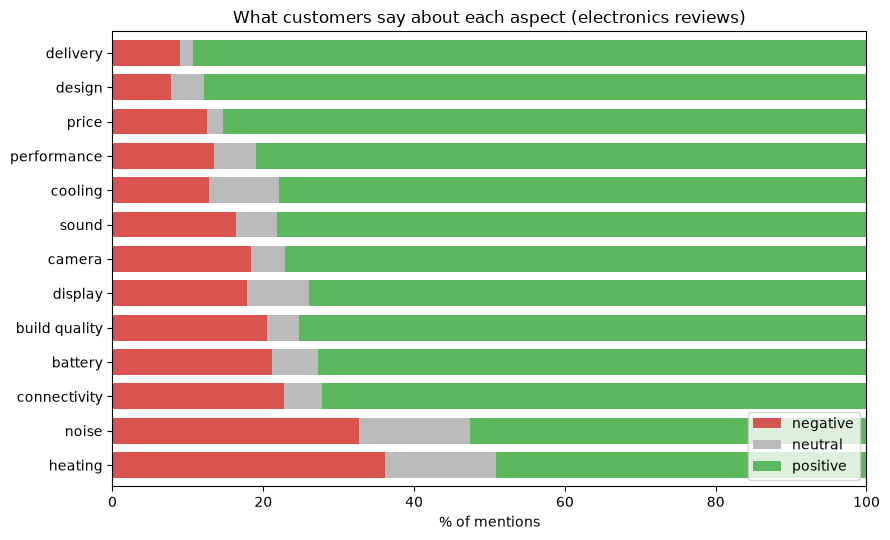

In [7]:
plot_df = summary.sort_values("net_score")[LABELS]
colors = {"negative": "#d9534f", "neutral": "#bbbbbb", "positive": "#5cb85c"}

ax = plot_df.plot(kind="barh", stacked=True, figsize=(9, 5.5),
                  color=[colors[c] for c in LABELS], width=0.75)
ax.set_xlabel("% of mentions")
ax.set_ylabel("")
ax.set_title("What customers say about each aspect (electronics reviews)")
ax.set_xlim(0, 100)
ax.legend(loc="lower right")
plt.tight_layout()

os.makedirs("reports", exist_ok=True)
plt.savefig("reports/aspect_sentiment.png", dpi=150)
plt.show()

**What to notice:** aspects at the top of the table are praised, aspects at the bottom have the most complaints. Think about *why*: for example, a "heating" or "delivery" mention is usually a complaint, because people mostly mention them when something goes wrong.

## Step 6: Check the quality by reading real examples

Never trust a number you have not checked against real text. Read the sample below and count how many predictions you agree with. A simple, honest report line is: "I manually checked 30 random aspect clauses and agreed with X of 30".

In [8]:
check = clauses.sample(min(30, len(clauses)), random_state=5)
check[["aspect", "clause", "sentiment"]].reset_index(drop=True)

,aspect,clause,sentiment
0,connectivity,awsome product thanks for the flipkart bugaet price range thanks for flipkart,positive
1,sound,bass not for gaming in pubg cause 1 second sound delay,neutral
2,display,wow its superb go for it it value for money nice quality perfect picture quality no need to hd c...,positive
3,delivery,prompt delivery satisfied value for money,positive
4,performance,this machine is beast with m1 chip monster fast speed processor with premium,positive
5,design,its design made it very tight and upper half is only for ice so you cant use it for daily essent...,negative
6,build quality,good quality product,positive
7,build quality,low quality,negative
8,price,best phone in lowest price,positive
9,connectivity,best valuable tv in this price range got delivery and installation in just one day,positive


**Write down:** how many of the 30 do you agree with? What kinds of mistakes do you see (clauses with no sentiment word, sarcasm, wrong aspect matched)?

## Step 7: Drill down into one product

This is what a seller or a buyer would actually want: the aspect profile of **one product**. Below we pick the product with the most reviews. Change `product` to any product name from your data.

In [9]:
def aspect_report(product, min_mentions=10):
    """Aspect sentiment table for one product (exact product name)."""
    sub = clauses[clauses["product_name"] == product]
    c = pd.crosstab(sub["aspect"], sub["sentiment"]).reindex(columns=LABELS, fill_value=0)
    total = c.sum(axis=1)
    out = (c.div(total, axis=0) * 100).round(1)
    out["mentions"] = total
    out["net_score"] = (out["positive"] - out["negative"]).round(1)
    return out[out["mentions"] >= min_mentions].sort_values("net_score", ascending=False)

product = clauses["product_name"].value_counts().index[0]
print("Product:", product[:90])
aspect_report(product)

Product: Mi 5A 80 cm (32 inch) HD Ready LED Smart Android TV with Dolby Audio (2022 Model)


sentiment,negative,neutral,positive,mentions,net_score
aspect,,,,,
price,6.6,1.0,92.3,768,85.7
delivery,9.9,0.8,89.3,253,79.4
design,6.0,8.6,85.3,116,79.3
sound,9.8,5.2,85.1,542,75.3
build quality,11.8,6.2,82.0,289,70.2
display,15.7,6.0,78.3,728,62.6
connectivity,23.5,6.5,70.1,558,46.6
performance,23.4,8.8,67.9,137,44.5
battery,40.9,4.5,54.5,22,13.6


If the table is short, that product has few aspect mentions. Try another product, or lower `min_mentions`.

## Step 8: Save the results

In [10]:
summary.to_csv("reports/aspect_sentiment.csv")
clauses[["review_id", "product_name", "aspect", "clause", "sentiment"]].to_csv(
    "data/processed/aspect_clauses.csv", index=False)
print("saved reports/aspect_sentiment.csv and data/processed/aspect_clauses.csv")

saved reports/aspect_sentiment.csv and data/processed/aspect_clauses.csv


## Limitations (good to state in your report)

- **Keyword method:** an aspect is found only if one of our listed words appears. New words or Hinglish are missed.
- **Many reviews have no aspect:** most reviews are general comments.
- **Model trained on whole reviews:** it scores clauses reasonably but not perfectly, especially the neutral class.
- **Matching can be wrong:** "hot" in "hot deal" would be tagged as heating; "range" in a price range would be tagged as connectivity.

**Ways to improve (future work):** learn aspects automatically with topic models or a transformer, and train on aspect-labelled data.

**Next:** a transformer model (DistilBERT) to compare with the classical models, and a small app to try reviews live.